In [ ]:
!pip install statsmodels tensorflow scikit-learn joblib -q
import os
os.makedirs("data", exist_ok=True)
os.makedirs("models", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

In [ ]:
"""
STEP 1: Preprocessing the  Fatigue Dataset
Run: python step1_preprocess.py
Produces: data/fatigue_clean.csv
"""
import pandas as pd
import numpy as np

RAW_PATH = "Fatigue_Dataset_150000.xlsx"
OUT_PATH = "data/fatigue_clean.csv"

def load_raw(path):
    df = pd.read_excel(path)
    print(f"Loaded raw: {df.shape}")
    return df

def clean(df):
    # 1. Drop rows with no employee/operation identity - can't use these
    before = len(df)
    df = df.dropna(subset=["EPF", "Employee_Name", "Operation"])
    print(f"Dropped {before - len(df)} rows missing EPF/Employee_Name/Operation")

    # 2. Fill remaining minor gaps
    df["Team"] = df["Team"].fillna("Unknown")
    df["Machine"] = df["Machine"].fillna("Unknown")
    df["Average_CT"] = df["Average_CT"].fillna(df.groupby("Operation")["Average_CT"].transform("median"))
    df["SMV"] = df["SMV"].fillna(df.groupby("Operation")["SMV"].transform("median"))

    # 3. Clip Skill_Factor outliers (dataset has garbage values up to 10000+,
    #    real skill factor scale should sit roughly 0-150). Clip at 1st/99th percentile.
    lo, hi = df["Skill_Factor"].quantile([0.01, 0.99])
    df["Skill_Factor"] = df["Skill_Factor"].clip(lo, hi)

    # 4. Convert Hour "08:00" -> hours_into_shift (0-8), shift starts at 08:00
    df["hour_num"] = df["Hour"].str.slice(0, 2).astype(int)
    df["hours_into_shift"] = df["hour_num"] - 8

    # 5. Fatigue_Score is a person-level physiological reading - if an employee
    #    logged two operations in the same hour, average the fatigue reading
    #    (skill/SMV/operation stay operation-specific and are handled separately
    #    in the skill matrix step).
    fatigue_ts = (
        df.groupby(["EPF", "Employee_Name", "Date", "hours_into_shift"])
        .agg(Fatigue_Score=("Fatigue_Score", "mean"),
             Efficiency=("Efficiency", "mean"),
             Productivity=("Productivity", "mean"),
             Quality_Score=("Quality_Score", "mean"))
        .reset_index()
        .sort_values(["EPF", "Date", "hours_into_shift"])
    )

    # 6. Skill matrix table: one row per (employee, operation) - use most recent
    #    reading of Skill_Factor per operation as their current skill level.
    skill_table = (
        df.sort_values("Date")
        .groupby(["EPF", "Employee_Name", "Operation"])
        .agg(Skill_Factor=("Skill_Factor", "last"),
             SMV=("SMV", "last"),
             Machine=("Machine", "last"))
        .reset_index()
    )

    return df, fatigue_ts, skill_table

if __name__ == "__main__":
    raw = load_raw(RAW_PATH)
    clean_full, fatigue_ts, skill_table = clean(raw)

    clean_full.to_csv("data/fatigue_clean_full.csv", index=False)
    fatigue_ts.to_csv("data/fatigue_timeseries.csv", index=False)
    skill_table.to_csv("data/skill_matrix_table.csv", index=False)

    print("\n--- Saved ---")
    print("data/fatigue_clean_full.csv  (all cleaned rows)")
    print("data/fatigue_timeseries.csv  (one fatigue reading per employee/date/hour) ->", fatigue_ts.shape)
    print("data/skill_matrix_table.csv  (employee x operation skill levels)       ->", skill_table.shape)

Loaded raw: (150000, 15)
Dropped 2313 rows missing EPF/Employee_Name/Operation


/tmp/ipykernel_2230/2178821052.py:24: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Team"] = df["Team"].fillna("Unknown")
/tmp/ipykernel_2230/2178821052.py:25: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Machine"] = df["Machine"].fillna("Unknown")
/tmp/ipykernel_2230/2178821052.py:26: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pan


--- Saved ---
data/fatigue_clean_full.csv  (all cleaned rows)
data/fatigue_timeseries.csv  (one fatigue reading per employee/date/hour) -> (120669, 8)
data/skill_matrix_table.csv  (employee x operation skill levels)       -> (7271, 6)


In [ ]:
"""
STEP 2: ARIMA baseline fatigue-curve model
Fits one small ARIMA model per operator's shift-level fatigue sequence,
then evaluates one-step-ahead forecast accuracy pooled across operators.

"""
import pandas as pd
import numpy as np
from statsmodels.tsa.arima.model import ARIMA
import warnings
warnings.filterwarnings("ignore")

df = pd.read_csv("data/fatigue_timeseries.csv")

# Build one ordered sequence per (employee, date) shift
df = df.sort_values(["EPF", "Date", "hours_into_shift"])

results = []
count_fitted = 0

# NOTE: fitting ARIMA per-shift is ~0.04s each; with 13,000+ shifts that's ~9 min.
# For a quick demo run we sample a subset. Remove SAMPLE_N (or set to None) to run
# on the full dataset for your final report numbers.
SAMPLE_N = 3000
groups = list(df.groupby(["EPF", "Date"]))
if SAMPLE_N:
    import random
    random.seed(42)
    groups = random.sample(groups, min(SAMPLE_N, len(groups)))

for (epf, date), grp in groups:
    series = grp["Fatigue_Score"].values
    if len(series) < 5:
        continue  # need enough points in the shift to fit + hold out test point

    train, test = series[:-1], series[-1]
    try:
        model = ARIMA(train, order=(1, 1, 1))
        fitted = model.fit()
        pred = fitted.forecast(steps=1)[0]
        results.append({"EPF": epf, "Date": date, "actual": test, "pred": pred})
        count_fitted += 1
    except Exception:
        continue

res_df = pd.DataFrame(results)
mae = np.mean(np.abs(res_df["actual"] - res_df["pred"]))
rmse = np.sqrt(np.mean((res_df["actual"] - res_df["pred"]) ** 2))

print(f"ARIMA fitted on {count_fitted} shift-sequences")
print(f"MAE:  {mae:.4f}")
print(f"RMSE: {rmse:.4f}")

res_df.to_csv("outputs/arima_results.csv", index=False)
with open("outputs/arima_metrics.txt", "w") as f:
    f.write(f"ARIMA(1,1,1) baseline fatigue forecaster\n")
    f.write(f"Sequences fitted: {count_fitted}\n")
    f.write(f"MAE:  {mae:.4f}\n")
    f.write(f"RMSE: {rmse:.4f}\n")

ARIMA fitted on 3000 shift-sequences
MAE:  0.0518
RMSE: 0.0654


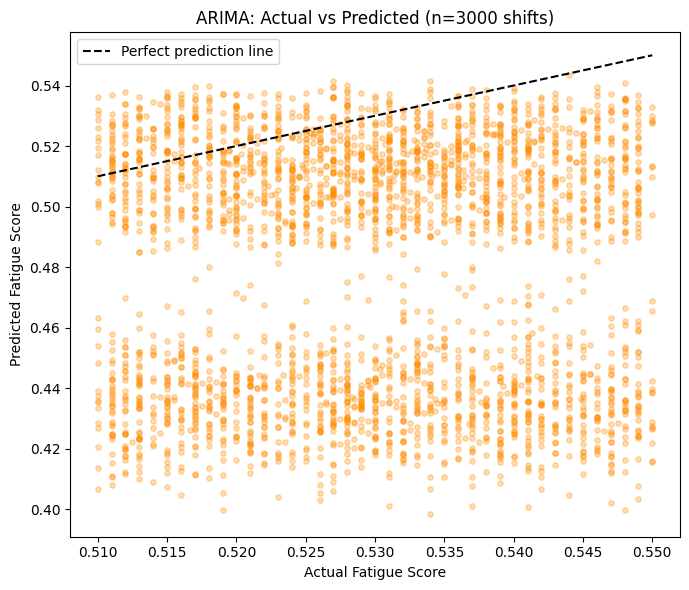

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 6))
plt.scatter(res_df["actual"], res_df["pred"], alpha=0.3, s=15, color="darkorange")
plt.plot([res_df["actual"].min(), res_df["actual"].max()],
         [res_df["actual"].min(), res_df["actual"].max()],
         'k--', label="Perfect prediction line")
plt.xlabel("Actual Fatigue Score")
plt.ylabel("Predicted Fatigue Score")
plt.title(f"ARIMA: Actual vs Predicted (n={len(res_df)} shifts)")
plt.legend()
plt.tight_layout()
plt.savefig("outputs/arima_actual_vs_predicted.png", dpi=120)
plt.show()

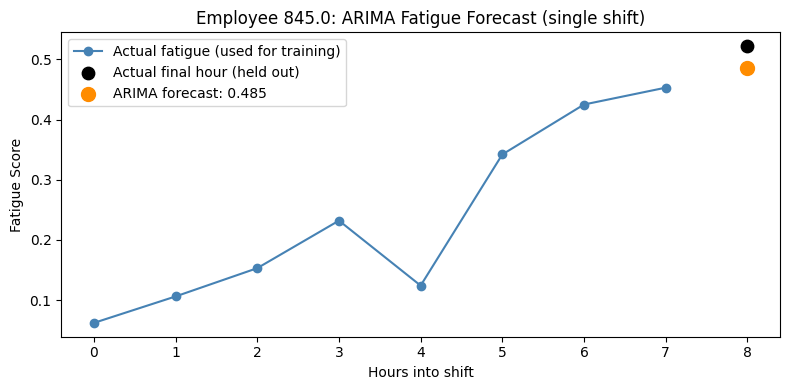

In [ ]:
from statsmodels.tsa.arima.model import ARIMA

sample_epf_arima = 845.0  # pick any real EPF
sample_hist_arima = fatigue_ts[fatigue_ts["EPF"] == sample_epf_arima].sort_values(["Date", "hours_into_shift"])
sample_hist_arima = sample_hist_arima[sample_hist_arima["Date"] == sample_hist_arima["Date"].iloc[0]]

hours_a = sample_hist_arima["hours_into_shift"].values
scores_a = sample_hist_arima["Fatigue_Score"].values

if len(scores_a) >= 5:
    train_a, test_a = scores_a[:-1], scores_a[-1]
    arima_single = ARIMA(train_a, order=(1, 1, 1)).fit()
    forecast_a = arima_single.forecast(steps=1)[0]

    plt.figure(figsize=(8, 4))
    plt.plot(hours_a[:-1], train_a, marker="o", label="Actual fatigue (used for training)", color="steelblue")
    plt.scatter([hours_a[-1]], [test_a], color="black", s=80, zorder=5, label="Actual final hour (held out)")
    plt.scatter([hours_a[-1]], [forecast_a], color="darkorange", s=100, zorder=5,
                label=f"ARIMA forecast: {forecast_a:.3f}")
    plt.xlabel("Hours into shift")
    plt.ylabel("Fatigue Score")
    plt.title(f"Employee {sample_epf_arima}: ARIMA Fatigue Forecast (single shift)")
    plt.legend()
    plt.tight_layout()
    plt.savefig("outputs/single_employee_arima_forecast.png", dpi=120)
    plt.show()
else:
    print("This employee's shift is too short - try a different EPF")

Built 67089 training sequences (window=4)
Epoch 1/50
755/755 - 9s - 12ms/step - loss: 0.0144 - mae: 0.0705 - val_loss: 0.0020 - val_mae: 0.0338
Epoch 2/50
755/755 - 6s - 8ms/step - loss: 0.0012 - mae: 0.0269 - val_loss: 0.0010 - val_mae: 0.0233
Epoch 3/50
755/755 - 5s - 7ms/step - loss: 9.0981e-04 - mae: 0.0232 - val_loss: 9.0409e-04 - val_mae: 0.0216
Epoch 4/50
755/755 - 6s - 8ms/step - loss: 8.0533e-04 - mae: 0.0220 - val_loss: 8.1088e-04 - val_mae: 0.0206
Epoch 5/50
755/755 - 10s - 13ms/step - loss: 7.3654e-04 - mae: 0.0211 - val_loss: 7.9662e-04 - val_mae: 0.0206
Epoch 6/50
755/755 - 6s - 8ms/step - loss: 7.4048e-04 - mae: 0.0212 - val_loss: 7.4515e-04 - val_mae: 0.0198
Epoch 7/50
755/755 - 10s - 13ms/step - loss: 7.1162e-04 - mae: 0.0207 - val_loss: 8.0190e-04 - val_mae: 0.0208
Epoch 8/50
755/755 - 9s - 12ms/step - loss: 6.9841e-04 - mae: 0.0205 - val_loss: 7.5419e-04 - val_mae: 0.0199
Epoch 9/50
755/755 - 6s - 8ms/step - loss: 6.8990e-04 - mae: 0.0205 - val_loss: 7.4406e-04 - val

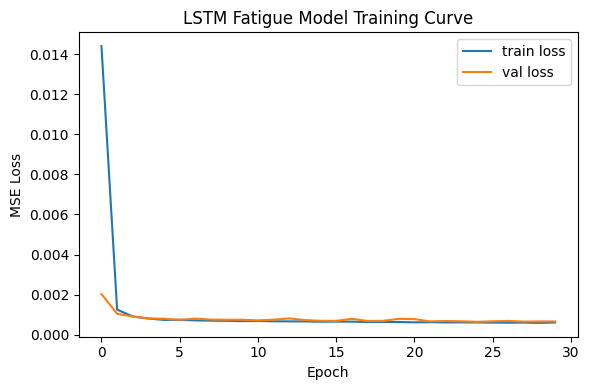

In [ ]:
"""
STEP 3: LSTM fatigue-curve model
Pools sequences across ALL operators (much more training data than ARIMA's
per-operator approach), learns a shared shift-fatigue pattern, and predicts
the next hour's fatigue score from a sliding window.
Run: python step3_lstm.py
"""
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
import matplotlib.pyplot as plt

WINDOW = 4  # use last 4 hourly readings to predict the 5th

df = pd.read_csv("data/fatigue_timeseries.csv")
df = df.sort_values(["EPF", "Date", "hours_into_shift"])

# Build (X, y) sequence pairs within each employee-shift
X, y = [], []
for (epf, date), grp in df.groupby(["EPF", "Date"]):
    series = grp["Fatigue_Score"].values
    if len(series) <= WINDOW:
        continue
    for i in range(len(series) - WINDOW):
        X.append(series[i:i + WINDOW])
        y.append(series[i + WINDOW])

X = np.array(X)
y = np.array(y)
print(f"Built {len(X)} training sequences (window={WINDOW})")

# Scale (fatigue score is already 0-1-ish, but scale properly for safety)
scaler = MinMaxScaler()
y_reshaped = y.reshape(-1, 1)
all_vals = np.concatenate([X.flatten(), y]).reshape(-1, 1)
scaler.fit(all_vals)

X_scaled = scaler.transform(X.reshape(-1, 1)).reshape(X.shape)
y_scaled = scaler.transform(y_reshaped).flatten()

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y_scaled, test_size=0.2, random_state=42
)
X_train = X_train.reshape((-1, WINDOW, 1))
X_test = X_test.reshape((-1, WINDOW, 1))

model = Sequential([
    LSTM(64, activation="tanh", input_shape=(WINDOW, 1), return_sequences=True),
    Dropout(0.2),
    LSTM(32, activation="tanh"),
    Dense(16, activation="relu"),
    Dense(1)
])
model.compile(optimizer="adam", loss="mse", metrics=["mae"])

es = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
history = model.fit(
    X_train, y_train,
    validation_split=0.1,
    epochs=50,
    batch_size=64,
    callbacks=[es],
    verbose=2
)

# Evaluate on held-out test set (inverse-transform back to real fatigue units)
pred_scaled = model.predict(X_test, verbose=0).flatten()
pred = scaler.inverse_transform(pred_scaled.reshape(-1, 1)).flatten()
actual = scaler.inverse_transform(y_test.reshape(-1, 1)).flatten()

mae = np.mean(np.abs(actual - pred))
rmse = np.sqrt(np.mean((actual - pred) ** 2))
print(f"\nLSTM Test MAE:  {mae:.4f}")
print(f"LSTM Test RMSE: {rmse:.4f}")

model.save("models/lstm_fatigue.keras")
import joblib
joblib.dump(scaler, "models/fatigue_scaler.pkl")

with open("outputs/lstm_metrics.txt", "w") as f:
    f.write("LSTM fatigue forecaster (window=4)\n")
    f.write(f"Train sequences: {len(X_train)}, Test sequences: {len(X_test)}\n")
    f.write(f"MAE:  {mae:.4f}\n")
    f.write(f"RMSE: {rmse:.4f}\n")

# Plot training curve
plt.figure(figsize=(6, 4))
plt.plot(history.history["loss"], label="train loss")
plt.plot(history.history["val_loss"], label="val loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("LSTM Fatigue Model Training Curve")
plt.legend()
plt.tight_layout()
plt.savefig("outputs/lstm_training_curve.png", dpi=120)
print("Saved: models/lstm_fatigue.keras, outputs/lstm_training_curve.png")

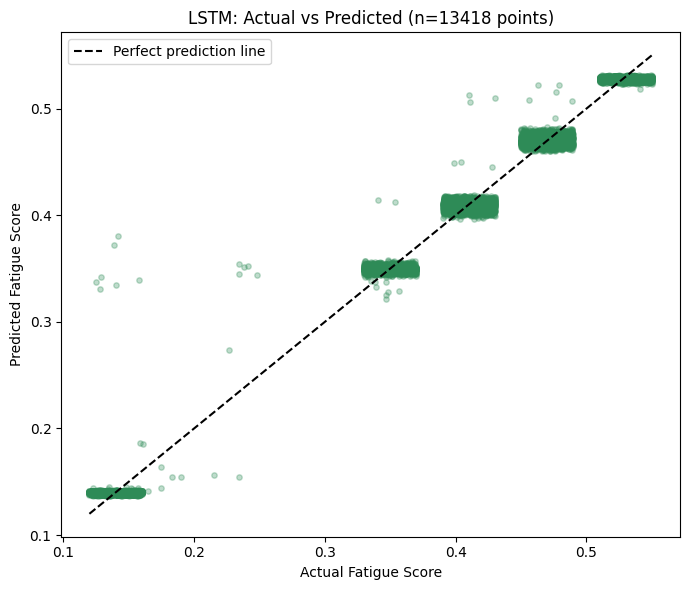

In [ ]:
plt.figure(figsize=(7, 6))
plt.scatter(actual, pred, alpha=0.3, s=15, color="seagreen")
plt.plot([actual.min(), actual.max()], [actual.min(), actual.max()],
         'k--', label="Perfect prediction line")
plt.xlabel("Actual Fatigue Score")
plt.ylabel("Predicted Fatigue Score")
plt.title(f"LSTM: Actual vs Predicted (n={len(actual)} points)")
plt.legend()
plt.tight_layout()
plt.savefig("outputs/lstm_actual_vs_predicted.png", dpi=120)
plt.show()

------------------------------------
Selected Employee : 16741.0
Shift Date        : 2025-11-19
Hours Recorded    : 18
Trend Slope       : 0.0308
------------------------------------


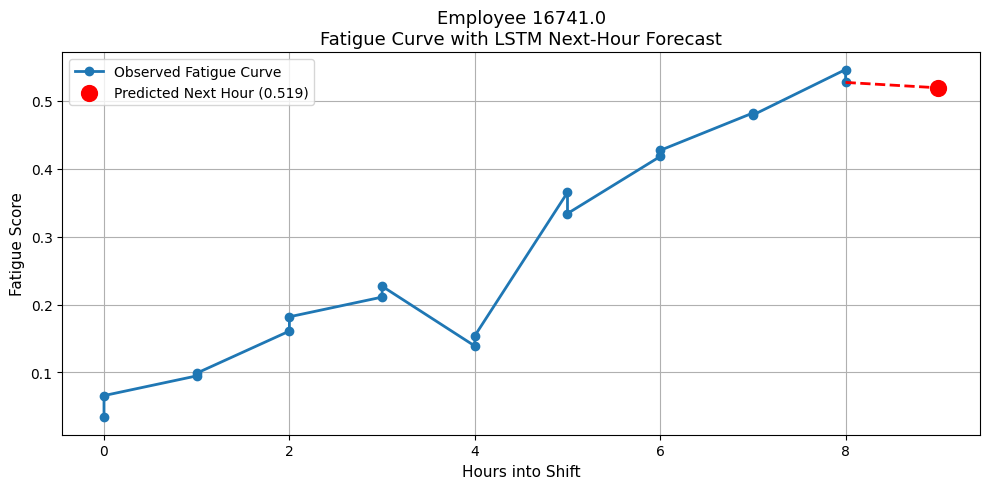


Saved:
outputs/lstm_best_employee_curve.png


In [ ]:
# ===============================================================
# Research Version
# Automatically choose the best employee shift for visualization
# ===============================================================

import numpy as np
import matplotlib.pyplot as plt

candidate_shifts = []

# ----------------------------------------------------------
# Examine every employee shift
# ----------------------------------------------------------
for (epf, date), grp in df.groupby(["EPF", "Date"]):

    grp = grp.sort_values("hours_into_shift")

    scores = grp["Fatigue_Score"].values

    # Need enough observations
    if len(scores) < WINDOW + 1:
        continue

    # ------------------------------------------------------
    # Calculate trend (positive = fatigue increasing)
    # ------------------------------------------------------
    x = np.arange(len(scores))

    slope = np.polyfit(x, scores, 1)[0]

    # Keep only increasing fatigue curves
    if slope > 0:

        candidate_shifts.append({

            "EPF": epf,

            "Date": date,

            "Length": len(scores),

            "Slope": slope

        })

# ----------------------------------------------------------
# No suitable employee?
# ----------------------------------------------------------
if len(candidate_shifts) == 0:

    print("No suitable fatigue curve found.")

else:

    # ------------------------------------------------------
    # Convert to DataFrame
    # ------------------------------------------------------
    candidate_df = pd.DataFrame(candidate_shifts)

    # Longest shifts first
    candidate_df = candidate_df.sort_values(
        ["Length", "Slope"],
        ascending=False
    )

    # Best shift
    best = candidate_df.iloc[0]

    sample_epf = best["EPF"]
    sample_date = best["Date"]

    print("------------------------------------")
    print("Selected Employee :", sample_epf)
    print("Shift Date        :", sample_date)
    print("Hours Recorded    :", best["Length"])
    print("Trend Slope       :", round(best["Slope"],4))
    print("------------------------------------")

    # ------------------------------------------------------
    # Load selected shift
    # ------------------------------------------------------
    sample_hist = df[
        (df["EPF"] == sample_epf) &
        (df["Date"] == sample_date)
    ].sort_values("hours_into_shift")

    hours = sample_hist["hours_into_shift"].values

    scores = sample_hist["Fatigue_Score"].values

    # ------------------------------------------------------
    # Predict next hour
    # ------------------------------------------------------
    last_window = scores[-WINDOW:]

    scaled_window = scaler.transform(
        last_window.reshape(-1,1)
    ).reshape(1, WINDOW, 1)

    pred_scaled = model.predict(
        scaled_window,
        verbose=0
    )[0][0]

    prediction = scaler.inverse_transform(
        [[pred_scaled]]
    )[0][0]

    next_hour = hours[-1] + 1

    # ------------------------------------------------------
    # Plot
    # ------------------------------------------------------
    plt.figure(figsize=(10,5))

    plt.plot(
        hours,
        scores,
        marker="o",
        linewidth=2,
        label="Observed Fatigue Curve"
    )

    plt.scatter(
        next_hour,
        prediction,
        color="red",
        s=130,
        zorder=5,
        label=f"Predicted Next Hour ({prediction:.3f})"
    )

    plt.plot(
        [hours[-1], next_hour],
        [scores[-1], prediction],
        "r--",
        linewidth=2
    )

    plt.xlabel("Hours into Shift", fontsize=11)

    plt.ylabel("Fatigue Score", fontsize=11)

    plt.title(
        f"Employee {sample_epf}\n"
        f"Fatigue Curve with LSTM Next-Hour Forecast",
        fontsize=13
    )

    plt.grid(True)

    plt.legend()

    plt.tight_layout()

    plt.savefig(
        "outputs/lstm_best_employee_curve.png",
        dpi=300
    )

    plt.show()

    print("\nSaved:")
    print("outputs/lstm_best_employee_curve.png")

In [ ]:
"""
STEP 4: Fatigue-Aware Skill Matrix Substitution Engine
Combines:
  - skill_matrix_table.csv  (employee x operation skill levels, from Step 1)
  - the trained LSTM        (predicts each employee's *next-hour* fatigue, from Step 3)
into a ranked list of replacement candidates for an absent operator.
Run: python step4_substitution.py
"""
import pandas as pd
import numpy as np
import joblib
from tensorflow.keras.models import load_model

skill_table = pd.read_csv("data/skill_matrix_table.csv")
fatigue_ts = pd.read_csv("data/fatigue_timeseries.csv")
lstm = load_model("models/lstm_fatigue.keras")
scaler = joblib.load("models/fatigue_scaler.pkl")

WINDOW = 4


def get_employee_skill_vector(epf, operations):
    """Return {operation: skill_factor} for a given employee, 0 if unknown."""
    rows = skill_table[skill_table["EPF"] == epf]
    vec = {op: 0.0 for op in operations}
    for _, r in rows.iterrows():
        if r["Operation"] in vec:
            vec[r["Operation"]] = r["Skill_Factor"]
    return vec


def predict_current_fatigue(epf):
    """Use the employee's most recent WINDOW fatigue readings to predict
    their next-hour fatigue via the trained LSTM. Falls back to their last
    known reading if not enough history exists."""
    hist = fatigue_ts[fatigue_ts["EPF"] == epf].sort_values(
        ["Date", "hours_into_shift"]
    )
    if len(hist) < WINDOW:
        return hist["Fatigue_Score"].iloc[-1] if len(hist) else 0.2  # neutral default

    last_window = hist["Fatigue_Score"].values[-WINDOW:]
    scaled = scaler.transform(last_window.reshape(-1, 1)).reshape(1, WINDOW, 1)
    pred_scaled = lstm.predict(scaled, verbose=0).flatten()[0]
    pred = scaler.inverse_transform([[pred_scaled]])[0][0]
    return pred


def compute_proximity_score(absent_skills, candidate_skills, operations, smv_weights):
    """Weighted Euclidean distance between skill vectors (Listing 6.2 logic).
    Lower = better skill match."""
    distance_sq = 0.0
    for op in operations:
        a = absent_skills.get(op, 0)
        c = candidate_skills.get(op, 0)
        w = smv_weights.get(op, 1.0)
        distance_sq += w * (a - c) ** 2
    return distance_sq ** 0.5


def fatigue_adjusted_score(base_score, predicted_fatigue, penalty_weight=2.0, fatigue_threshold=0.2):
    """Add a penalty proportional to how far above a 'fresh' baseline the
    candidate's predicted fatigue is. fatigue_threshold ~ typical fresh-shift level."""
    penalty = penalty_weight * max(0.0, predicted_fatigue - fatigue_threshold)
    return base_score + penalty


def rank_replacements(absent_epf, candidate_epfs, operations, smv_weights):
    absent_skills = get_employee_skill_vector(absent_epf, operations)
    results = []
    for cand in candidate_epfs:
        cand_skills = get_employee_skill_vector(cand, operations)
        base = compute_proximity_score(absent_skills, cand_skills, operations, smv_weights)
        fatigue = predict_current_fatigue(cand)
        adjusted = fatigue_adjusted_score(base, fatigue)
        results.append({
            "candidate_EPF": cand,
            "skill_distance": round(base, 4),
            "predicted_fatigue": round(fatigue, 4),
            "fatigue_adjusted_score": round(adjusted, 4),
        })
    return sorted(results, key=lambda x: x["fatigue_adjusted_score"])


if __name__ == "__main__":
    # ---- DEMO: pick a real absent operator + real candidates from the dataset ----
    sample_op_group = skill_table.groupby("Operation")["EPF"].apply(list)
    # pick an operation with enough candidates to make the demo meaningful
    op_name = sample_op_group[sample_op_group.apply(len) >= 6].index[0]
    pool = sample_op_group[op_name][:6]

    absent = pool[0]
    candidates = pool[1:]
    operations = [op_name]
    smv_weights = {op_name: 1.0}

    print(f"Absent operator EPF: {absent}  |  Operation: {op_name}")
    print(f"Candidate pool: {candidates}\n")

    ranked = rank_replacements(absent, candidates, operations, smv_weights)
    ranked_df = pd.DataFrame(ranked)
    print(ranked_df.to_string(index=False))
    ranked_df.to_csv("outputs/sample_replacement_ranking.csv", index=False)
    print("\nSaved: outputs/sample_replacement_ranking.csv")

Absent operator EPF: 109.0  |  Operation: Apply Back Heat seal
Candidate pool: [387.0, 832.0, 845.0, 853.0, 930.0]

 candidate_EPF  skill_distance  predicted_fatigue  fatigue_adjusted_score
         845.0            0.94             0.5271                  1.5941
         387.0            5.32             0.5265                  5.9730
         832.0            8.60             0.5264                  9.2528
         930.0           27.42             0.5266                 28.0732
         853.0           32.55             0.5255                 33.2009

Saved: outputs/sample_replacement_ranking.csv


In [ ]:
absent_skills = {'Attach Collar': 5, 'Sew Side Seams': 3}
candidates = {
    'Operator B (skilled, tired)':   {'skills': {'Attach Collar': 5, 'Sew Side Seams': 4}, 'fatigue': 0.48},
    'Operator C (slightly less skilled, fresh)': {'skills': {'Attach Collar': 4, 'Sew Side Seams': 3}, 'fatigue': 0.08},
}
smv_weights = {'Attach Collar': 1.2, 'Sew Side Seams': 0.8}

rows = []
for name, c in candidates.items():
    base = compute_proximity_score(absent_skills, c['skills'], absent_skills.keys(), smv_weights)
    adj = fatigue_adjusted_score(base, c['fatigue'])
    rows.append((name, base, c['fatigue'], adj))

print(f'{"Candidate":45s} {"SkillDist":>10s} {"Fatigue":>8s} {"FatigueAdjScore":>16s}')
for r in sorted(rows, key=lambda r: r[3]):
    print(f'{r[0]:45s} {r[1]:10.3f} {r[2]:8.3f} {r[3]:16.3f}')

Candidate                                      SkillDist  Fatigue  FatigueAdjScore
Operator C (slightly less skilled, fresh)          1.095    0.080            1.095
Operator B (skilled, tired)                        0.894    0.480            1.454


In [ ]:
def find_best_replacement(absent_epf, top_n=5):
    absent_rows = skill_table[skill_table["EPF"] == absent_epf]
    if absent_rows.empty:
        return f"No skill record found for EPF {absent_epf}"

    all_results = []
    for _, row in absent_rows.iterrows():
        operation = row["Operation"]
        pool = skill_table[
            (skill_table["Operation"] == operation) &
            (skill_table["EPF"] != absent_epf)
        ]["EPF"].unique().tolist()

        if not pool:
            continue

        operations = [operation]
        smv_weights = {operation: 1.0}
        ranked = rank_replacements(absent_epf, pool, operations, smv_weights)
        for r in ranked:
            r["operation"] = operation
        all_results.extend(ranked)

    all_results = sorted(all_results, key=lambda x: x["fatigue_adjusted_score"])
    return pd.DataFrame(all_results).head(top_n)


find_best_replacement(absent_epf=109.0, top_n=5)

,candidate_EPF,skill_distance,predicted_fatigue,fatigue_adjusted_score,operation
0,6326.0,0.08,0.5260,0.7321,Apply Heat seal
1,17516.0,0.14,0.5256,0.7913,Apply Back Heat seal
2,6326.0,0.15,0.5260,0.8021,Apply Back Heat seal
3,6013.0,0.15,0.5270,0.8040,Apply Heat seal
4,3194.0,0.20,0.5270,0.8540,Apply Heat seal


In [ ]:
find_best_replacement(absent_epf=387.0, top_n=5)

,candidate_EPF,skill_distance,predicted_fatigue,fatigue_adjusted_score,operation
0,16895.0,0.01,0.5258,0.6616,Apply Back Heat seal
1,19043.0,0.04,0.5265,0.6929,Apply Back Heat seal
2,11523.0,0.05,0.5265,0.7029,Attach Labels
3,10565.0,0.20,0.5267,0.8533,Attach Labels
4,15702.0,0.48,0.5260,1.1320,Apply Back Heat seal


In [ ]:
from sklearn.metrics import r2_score, mean_absolute_percentage_error

# ---- LSTM accuracy (you already have `actual` and `pred` from Step 3) ----
lstm_mape = mean_absolute_percentage_error(actual, pred)
lstm_accuracy = (1 - lstm_mape) * 100
lstm_r2 = r2_score(actual, pred) * 100

print("=== LSTM ===")
print(f"Accuracy (based on MAPE): {lstm_accuracy:.2f}%")
print(f"R² score (variance explained): {lstm_r2:.2f}%")

# ---- ARIMA accuracy (you already have `res_df` from Step 2) ----
arima_mape = mean_absolute_percentage_error(res_df["actual"], res_df["pred"])
arima_accuracy = (1 - arima_mape) * 100
arima_r2 = r2_score(res_df["actual"], res_df["pred"]) * 100

print("\n=== ARIMA ===")
print(f"Accuracy (based on MAPE): {arima_accuracy:.2f}%")
print(f"R² score (variance explained): {arima_r2:.2f}%")

=== LSTM ===
Accuracy (based on MAPE): 96.69%
R² score (variance explained): 99.11%

=== ARIMA ===
Accuracy (based on MAPE): 90.25%
R² score (variance explained): -3412.66%


In [ ]:
import numpy as np

def predict_custom_fatigue(hour1, hour2, hour3, hour4):
    """
    Give it 4 fatigue readings (e.g. from hours 1-4 of a shift) and it
    predicts what hour 5's fatigue will be.
    Fatigue values are typically in the 0.03-0.55 range in this dataset.
    """
    raw_input = np.array([hour1, hour2, hour3, hour4])
    scaled_input = scaler.transform(raw_input.reshape(-1, 1)).reshape(1, 4, 1)
    pred_scaled = lstm.predict(scaled_input, verbose=0).flatten()[0]
    pred = scaler.inverse_transform([[pred_scaled]])[0][0]
    return pred

# ---- TRY IT: change these 4 numbers to whatever you want ----
result = predict_custom_fatigue(0.10, 0.15, 0.22, 0.28)
print(f"Predicted next-hour fatigue: {result:.4f}")

Predicted next-hour fatigue: 0.3505


In [ ]:
import numpy as np

def predict_custom_fatigue(hour1, hour2, hour3, hour4):
    """
    Give it 4 fatigue readings (e.g. from hours 1-4 of a shift) and it
    predicts what hour 5's fatigue will be.
    Fatigue values are typically in the 0.03-0.55 range in this dataset.
    """
    raw_input = np.array([hour1, hour2, hour3, hour4])
    scaled_input = scaler.transform(raw_input.reshape(-1, 1)).reshape(1, 4, 1)
    pred_scaled = lstm.predict(scaled_input, verbose=0).flatten()[0]
    pred = scaler.inverse_transform([[pred_scaled]])[0][0]
    return pred

# ---- TRY IT: change these 4 numbers to whatever you want ----
result = predict_custom_fatigue(0.05, 0.06, 0.07, 0.08)
print(f"Predicted next-hour fatigue: {result:.4f}")

Predicted next-hour fatigue: 0.1856


In [ ]:
import numpy as np

def predict_custom_fatigue(hour1, hour2, hour3, hour4):
    """
    Give it 4 fatigue readings (e.g. from hours 1-4 of a shift) and it
    predicts what hour 5's fatigue will be.
    Fatigue values are typically in the 0.03-0.55 range in this dataset.
    """
    raw_input = np.array([hour1, hour2, hour3, hour4])
    scaled_input = scaler.transform(raw_input.reshape(-1, 1)).reshape(1, 4, 1)
    pred_scaled = lstm.predict(scaled_input, verbose=0).flatten()[0]
    pred = scaler.inverse_transform([[pred_scaled]])[0][0]
    return pred

# ---- TRY IT: change these 4 numbers to whatever you want ----
result = predict_custom_fatigue(0.30, 0.38, 0.45, 0.50)
print(f"Predicted next-hour fatigue: {result:.4f}")

Predicted next-hour fatigue: 0.5262


In [ ]:
from sklearn.metrics import r2_score, mean_absolute_percentage_error

lstm_mape = mean_absolute_percentage_error(actual, pred)
lstm_accuracy = (1 - lstm_mape) * 100
lstm_r2 = r2_score(actual, pred) * 100

print("=== LSTM ===")
print(f"Accuracy (based on MAPE): {lstm_accuracy:.2f}%")
print(f"R² score: {lstm_r2:.2f}%")

arima_mape = mean_absolute_percentage_error(res_df["actual"], res_df["pred"])
arima_accuracy = (1 - arima_mape) * 100
arima_r2 = r2_score(res_df["actual"], res_df["pred"]) * 100

print("\n=== ARIMA ===")
print(f"Accuracy (based on MAPE): {arima_accuracy:.2f}%")
print(f"R² score: {arima_r2:.2f}%")

=== LSTM ===
Accuracy (based on MAPE): 96.69%
R² score: 99.11%

=== ARIMA ===
Accuracy (based on MAPE): 90.25%
R² score: -3412.66%


In [ ]:
# Manually verify the weighted Euclidean distance formula
absent_skills = {'Attach Collar': 5}
candidate_skills = {'Attach Collar': 3}
smv_weights = {'Attach Collar': 1.0}

# By hand: distance = sqrt(weight * (absent - candidate)^2) = sqrt(1.0 * (5-3)^2) = sqrt(4) = 2.0
manual_calc = (1.0 * (5 - 3)**2) ** 0.5
function_calc = compute_proximity_score(absent_skills, candidate_skills, ['Attach Collar'], smv_weights)

print(f"Manual calculation: {manual_calc}")
print(f"Function output:    {function_calc}")
print("MATCH ✓" if manual_calc == function_calc else "MISMATCH ✗ — something's wrong")

Manual calculation: 2.0
Function output:    2.0
MATCH ✓


In [ ]:
# Same skill match, but one is tired, one is fresh - fresh one MUST win
base_score = 2.0  # same skill distance for both

fresh_score = fatigue_adjusted_score(base_score, predicted_fatigue=0.05)
tired_score = fatigue_adjusted_score(base_score, predicted_fatigue=0.50)

print(f"Fresh candidate's final score: {fresh_score}")
print(f"Tired candidate's final score: {tired_score}")
print("CORRECT ✓ - fresh wins" if fresh_score < tired_score else "BUG ✗ - tired wrongly wins")

Fresh candidate's final score: 2.0
Tired candidate's final score: 2.6
CORRECT ✓ - fresh wins


In [ ]:
# Case A: absent person doesn't exist in the skill table
print(find_best_replacement(absent_epf=999999999.0, top_n=5))

# Case B: does the top result actually make logical sense?
result = find_best_replacement(absent_epf=109.0, top_n=5)
print(result)
print("\nIs it sorted correctly (best/lowest score first)?",
      result["fatigue_adjusted_score"].is_monotonic_increasing)

No skill record found for EPF 999999999.0
   candidate_EPF  skill_distance  predicted_fatigue  fatigue_adjusted_score  \
0         6326.0            0.08             0.5260                  0.7321   
1        17516.0            0.14             0.5256                  0.7913   
2         6326.0            0.15             0.5260                  0.8021   
3         6013.0            0.15             0.5270                  0.8040   
4         3194.0            0.20             0.5270                  0.8540   

              operation  
0       Apply Heat seal  
1  Apply Back Heat seal  
2  Apply Back Heat seal  
3       Apply Heat seal  
4       Apply Heat seal  

Is it sorted correctly (best/lowest score first)? True


Test Accuracy: 63.74%

Classification report:
              precision    recall  f1-score   support

           A       0.68      0.65      0.66      7425
           B       0.50      0.64      0.56      7364
           C       0.63      0.53      0.58      7408
           D       0.79      0.73      0.76      7339

    accuracy                           0.64     29536
   macro avg       0.65      0.64      0.64     29536
weighted avg       0.65      0.64      0.64     29536


Feature importance:
Fatigue_Score       0.485682
hours_into_shift    0.470796
Efficiency_Ratio    0.015536
CT_Consistency      0.014539
Skill_Factor        0.013446
dtype: float64

Saved: models/quality_classifier_v3_FINAL.pkl


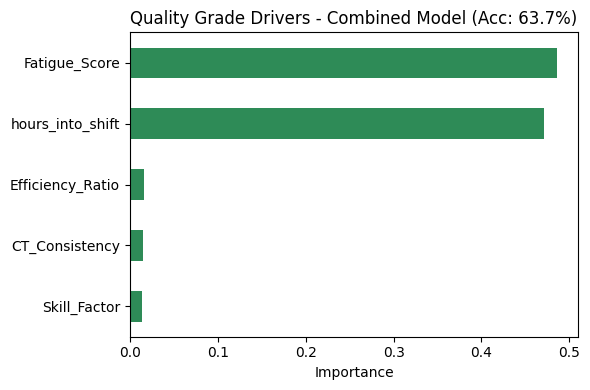

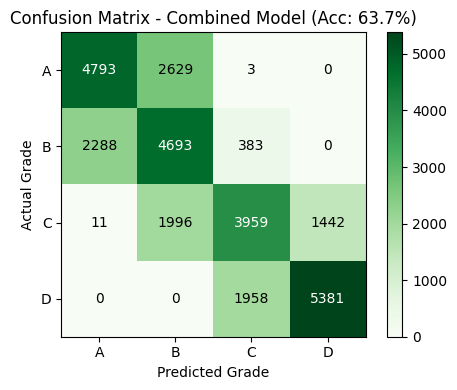

In [ ]:
"""
STEP 5 (FINAL): Quality Rank Classifier - combined feature set
"""
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import joblib

df = pd.read_csv("data/fatigue_clean_full.csv")

df = df[df["SMV"] > 0].copy()
ct_cap = df["Average_CT"].quantile(0.99)
df["Average_CT_clipped"] = df["Average_CT"].clip(upper=ct_cap)
df["Efficiency_Ratio"] = df["SMV"] / df["Average_CT_clipped"]

consistency = (
    df.groupby(["EPF", "Operation"])["Average_CT_clipped"]
    .std().reset_index().rename(columns={"Average_CT_clipped": "CT_Consistency"})
)
df = df.merge(consistency, on=["EPF", "Operation"], how="left")
df["CT_Consistency"] = df["CT_Consistency"].fillna(df["CT_Consistency"].median())

q25, q50, q75 = df["Quality_Score"].quantile([0.25, 0.5, 0.75])
def grade_from_score(score):
    if score >= q75: return "A"
    elif score >= q50: return "B"
    elif score >= q25: return "C"
    else: return "D"
df["Quality_Grade"] = df["Quality_Score"].apply(grade_from_score)

features = ["Skill_Factor", "Fatigue_Score", "hours_into_shift", "Efficiency_Ratio", "CT_Consistency"]
X = df[features].fillna(df[features].median())
y = df["Quality_Grade"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

clf = RandomForestClassifier(n_estimators=200, max_depth=10, random_state=42, n_jobs=-1)
clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)
acc = accuracy_score(y_test, y_pred)
print(f"Test Accuracy: {acc*100:.2f}%")
print("\nClassification report:")
print(classification_report(y_test, y_pred))

importances = pd.Series(clf.feature_importances_, index=features).sort_values(ascending=False)
print("\nFeature importance:")
print(importances)

plt.figure(figsize=(6, 4))
importances.plot(kind="barh", color="seagreen")
plt.xlabel("Importance")
plt.title(f"Quality Grade Drivers - Combined Model (Acc: {acc*100:.1f}%)")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("outputs/quality_feature_importance_v3.png", dpi=120)

cm = confusion_matrix(y_test, y_pred, labels=["A", "B", "C", "D"])
plt.figure(figsize=(5, 4))
plt.imshow(cm, cmap="Greens")
plt.xticks(range(4), ["A", "B", "C", "D"]); plt.yticks(range(4), ["A", "B", "C", "D"])
plt.xlabel("Predicted Grade"); plt.ylabel("Actual Grade")
plt.title(f"Confusion Matrix - Combined Model (Acc: {acc*100:.1f}%)")
for i in range(4):
    for j in range(4):
        plt.text(j, i, cm[i, j], ha="center", va="center",
                  color="white" if cm[i, j] > cm.max()/2 else "black")
plt.colorbar()
plt.tight_layout()
plt.savefig("outputs/quality_confusion_matrix_v3.png", dpi=120)

joblib.dump(clf, "models/quality_classifier_v3_FINAL.pkl")
with open("outputs/quality_classifier_v3_metrics.txt", "w") as f:
    f.write("Quality Rank Classifier v3 FINAL (combined features)\n")
    f.write(f"Test Accuracy: {acc*100:.2f}%\n\nFeature importance:\n{importances.to_string()}\n")

print("\nSaved: models/quality_classifier_v3_FINAL.pkl")

In [ ]:
def predict_quality_grade(skill_factor, fatigue_score, hours_into_shift, efficiency_ratio, ct_consistency):
    """Use the trained quality classifier to predict A/B/C/D grade."""
    features = pd.DataFrame([{
        "Skill_Factor": skill_factor,
        "Fatigue_Score": fatigue_score,
        "hours_into_shift": hours_into_shift,
        "Efficiency_Ratio": efficiency_ratio,
        "CT_Consistency": ct_consistency,
    }])
    return clf.predict(features)[0]


def find_best_replacement_with_quality(absent_epf, top_n=5):
    """Same as find_best_replacement, but also shows predicted quality grade
    for each candidate using their current fatigue + skill profile."""
    base_results = find_best_replacement(absent_epf, top_n=top_n)

    quality_grades = []
    for _, row in base_results.iterrows():
        cand_epf = row["candidate_EPF"]
        # look up this candidate's typical efficiency/consistency from the data
        cand_data = df[df["EPF"] == cand_epf]
        if cand_data.empty:
            quality_grades.append("Unknown")
            continue
        eff = cand_data["Efficiency_Ratio"].median()
        cons = cand_data["CT_Consistency"].median()
        skill = cand_data["Skill_Factor"].median()
        grade = predict_quality_grade(skill, row["predicted_fatigue"], 4, eff, cons)
        quality_grades.append(grade)

    base_results["predicted_quality_grade"] = quality_grades
    return base_results


# Try it
find_best_replacement_with_quality(absent_epf=109.0, top_n=5)

In [ ]:
!zip -r nextech_fatigue_FINAL.zip data models outputs -q
from google.colab import files
files.download("nextech_fatigue_FINAL.zip")

In [ ]:
print(f"Total records: {len(X)}")
print(f"Train (80%): {len(X_train)} records")
print(f"Test (20%): {len(X_test)} records — model never saw these during training")

print("\nGrade distribution in TRAIN set:")
print(y_train.value_counts(normalize=True).round(3))

print("\nGrade distribution in TEST set:")
print(y_test.value_counts(normalize=True).round(3))

In [ ]:
print(f"Test Accuracy: {acc*100:.2f}%")

In [ ]:
"""
STEP 4B: WORKSTATION-DRIVEN SUBSTITUTION
=========================================
Old direction : find_best_replacement(absent_epf)      -> "who can replace EPF 109?"
New direction : recommend_for_station(operation, ...)   -> "this station needs a body, who?"

Paste this AFTER Step 4 (needs: skill_table, predict_current_fatigue,
fatigue_adjusted_score) and AFTER Step 5 if you want quality grades (needs: df, clf).
"""
import pandas as pd
import numpy as np

# ---------------------------------------------------------------------------
# 0. Tunables  (put these in your report - examiners love an explicit weight table)
# ---------------------------------------------------------------------------
W_SKILL      = 0.45   # can they actually do the job to standard
W_FATIGUE    = 0.30   # will they hold up for the rest of the shift
W_EFFICIENCY = 0.25   # do they hit the SMV target on this operation
TRANSFER_PENALTY = 0.25   # applied to cross-trained (same machine, other operation) people
REQ_SKILL_PCTILE = 0.75   # "standard" for a station = 75th pct skill of people who run it
FRESH_FATIGUE    = 0.20   # below this = fresh (same threshold Step 4 uses)
FATIGUE_RANGE    = 0.35   # 0.20 -> 0.55 spans the observed tail

_fatigue_cache = {}   # LSTM is slow; never predict the same EPF twice


def cached_fatigue(epf):
    if epf not in _fatigue_cache:
        _fatigue_cache[epf] = float(predict_current_fatigue(epf))
    return _fatigue_cache[epf]


# ---------------------------------------------------------------------------
# 1. WORKSTATION PROFILES
#    Your dataset has no Workstation column, so a station IS (Operation, Machine).
#    That pair is what physically sits on the line, and it is what a supervisor
#    points at when they say "station 7 is empty".
# ---------------------------------------------------------------------------
station_profile = (
    skill_table.groupby(["Operation", "Machine"])
    .agg(
        req_skill=("Skill_Factor", lambda s: s.quantile(REQ_SKILL_PCTILE)),
        station_SMV=("SMV", "median"),
        n_trained=("EPF", "nunique"),
    )
    .reset_index()
)

# per-operator, per-operation history (efficiency + consistency + quality)
try:
    operator_stats = (
        df.groupby(["EPF", "Operation"])
        .agg(
            Efficiency_Ratio=("Efficiency_Ratio", "median"),
            CT_Consistency=("CT_Consistency", "median"),
            Quality_Score=("Quality_Score", "median"),
        )
        .reset_index()
    )
    op_eff_target = operator_stats.groupby("Operation")["Efficiency_Ratio"].quantile(
        REQ_SKILL_PCTILE
    )
    HAVE_EFF = True
except (NameError, KeyError):
    operator_stats, op_eff_target, HAVE_EFF = None, None, False
    print("NOTE: Step 5 not run yet -> efficiency term disabled, "
          "skill + fatigue only.")

print(f"Built {len(station_profile)} workstation profiles "
      f"({station_profile['Operation'].nunique()} operations x machines)")


# ---------------------------------------------------------------------------
# 2. CANDIDATE POOL FOR A STATION
#    Tier 1 = has actually run this operation before (no transfer penalty)
#    Tier 2 = cross-trained: runs a different operation on the SAME machine type
#             (gets TRANSFER_PENALTY) - this is what saves you when tier 1 is empty
# ---------------------------------------------------------------------------
def build_candidate_pool(operation, machine=None, allow_cross_trained=True,
                         exclude_epfs=()):
    exclude = set(float(e) for e in exclude_epfs)

    tier1 = skill_table[skill_table["Operation"] == operation]
    if machine is not None:
        tier1 = tier1[tier1["Machine"] == machine]
    pool = [
        {"EPF": r["EPF"], "Employee_Name": r["Employee_Name"],
         "Skill_Factor": r["Skill_Factor"], "source": "trained",
         "known_operation": operation}
        for _, r in tier1.iterrows() if r["EPF"] not in exclude
    ]

    if allow_cross_trained and machine is not None:
        seen = {p["EPF"] for p in pool}
        tier2 = skill_table[
            (skill_table["Machine"] == machine)
            & (skill_table["Operation"] != operation)
        ]
        # keep each person's best row only
        tier2 = tier2.sort_values("Skill_Factor", ascending=False).drop_duplicates("EPF")
        for _, r in tier2.iterrows():
            if r["EPF"] in seen or r["EPF"] in exclude:
                continue
            pool.append({"EPF": r["EPF"], "Employee_Name": r["Employee_Name"],
                         "Skill_Factor": r["Skill_Factor"], "source": "cross_trained",
                         "known_operation": r["Operation"]})
    return pool


# ---------------------------------------------------------------------------
# 3. STATION-FIT SCORE (lower = better, same convention as Step 4)
#    NOTE the important design change vs Step 4: we are no longer measuring
#    *closeness* to an absent person. A station has a REQUIREMENT, so being
#    over-skilled is not a defect - only the shortfall is penalised.
# ---------------------------------------------------------------------------
def station_fit_score(cand, req_skill, operation, eff_target):
    skill_gap = np.clip((req_skill - cand["Skill_Factor"]) / max(req_skill, 1e-6), 0, 1)

    fatigue = cached_fatigue(cand["EPF"])
    fatigue_term = np.clip((fatigue - FRESH_FATIGUE) / FATIGUE_RANGE, 0, 1)

    eff_term, cand_eff = 0.0, np.nan
    if HAVE_EFF and eff_target and eff_target > 0:
        row = operator_stats[
            (operator_stats["EPF"] == cand["EPF"])
            & (operator_stats["Operation"] == operation)
        ]
        if not row.empty:
            cand_eff = float(row["Efficiency_Ratio"].iloc[0])
            eff_term = np.clip((eff_target - cand_eff) / eff_target, 0, 1)
        else:
            eff_term = 0.5   # unknown on this operation -> neutral-bad

    score = (W_SKILL * skill_gap
             + W_FATIGUE * fatigue_term
             + W_EFFICIENCY * eff_term)
    if cand["source"] == "cross_trained":
        score += TRANSFER_PENALTY

    return {
        "EPF": cand["EPF"],
        "Employee_Name": cand["Employee_Name"],
        "source": cand["source"],
        "known_operation": cand["known_operation"],
        "skill_factor": round(float(cand["Skill_Factor"]), 2),
        "required_skill": round(float(req_skill), 2),
        "skill_gap": round(float(skill_gap), 3),
        "predicted_fatigue": round(fatigue, 4),
        "efficiency_ratio": round(cand_eff, 3) if not np.isnan(cand_eff) else None,
        "station_fit_score": round(float(score), 4),
        "suitability_pct": round(float(max(0.0, 1 - score)) * 100, 1),
    }


# ---------------------------------------------------------------------------
# 4. MAIN ENTRY POINT - this is the one your UI / supervisor calls
# ---------------------------------------------------------------------------
def recommend_for_station(operation, machine=None, required_skill=None,
                          top_n=5, allow_cross_trained=True, exclude_epfs=(),
                          with_quality=False):
    """
    'Station running <operation> on <machine> needs an operator' -> ranked top_n.

    operation       : e.g. "Attach Collar"          (required)
    machine         : e.g. "SNLS"  -> None = any machine used for that operation
    required_skill  : override the auto standard if the planner knows the target
    exclude_epfs    : people already assigned elsewhere / absent / on leave
    """
    prof = station_profile[station_profile["Operation"] == operation]
    if machine is not None:
        prof = prof[prof["Machine"] == machine]
    if prof.empty:
        return f"No station profile for operation='{operation}', machine='{machine}'"

    req_skill = (required_skill if required_skill is not None
                 else float(prof["req_skill"].max()))
    eff_target = float(op_eff_target.get(operation, np.nan)) if HAVE_EFF else None
    if eff_target is not None and np.isnan(eff_target):
        eff_target = None

    pool = build_candidate_pool(operation, machine, allow_cross_trained, exclude_epfs)
    if not pool:
        return f"No candidate operator available for '{operation}' / '{machine}'"

    ranked = [station_fit_score(c, req_skill, operation, eff_target) for c in pool]
    out = (pd.DataFrame(ranked)
           .sort_values("station_fit_score")
           .head(top_n)
           .reset_index(drop=True))
    out.insert(0, "rank", out.index + 1)

    if with_quality:
        grades = []
        for _, r in out.iterrows():
            cd = df[df["EPF"] == r["EPF"]] if "df" in globals() else pd.DataFrame()
            if cd.empty:
                grades.append("Unknown")
                continue
            grades.append(predict_quality_grade(
                cd["Skill_Factor"].median(), r["predicted_fatigue"], 4,
                cd["Efficiency_Ratio"].median(), cd["CT_Consistency"].median()))
        out["predicted_quality_grade"] = grades

    return out


# ---------------------------------------------------------------------------
# 5. MULTI-STATION FILL (greedy, no double-booking)
#    Fill the scarcest station first, then lock that person out of the rest.
# ---------------------------------------------------------------------------
def fill_open_stations(open_stations, exclude_epfs=(), top_n=3):
    """open_stations: [("Attach Collar", "SNLS"), ("Sew Side Seams", None), ...]"""
    taken = set(float(e) for e in exclude_epfs)
    rows = []

    def scarcity(s):
        p = station_profile[station_profile["Operation"] == s[0]]
        if s[1] is not None:
            p = p[p["Machine"] == s[1]]
        return p["n_trained"].sum()

    for op, mc in sorted(open_stations, key=scarcity):
        res = recommend_for_station(op, mc, top_n=top_n, exclude_epfs=taken)
        if isinstance(res, str):
            rows.append({"operation": op, "machine": mc, "assigned_EPF": None,
                         "assigned_name": "UNFILLED", "reason": res})
            continue
        best = res.iloc[0]
        taken.add(best["EPF"])
        rows.append({
            "operation": op, "machine": mc,
            "assigned_EPF": best["EPF"], "assigned_name": best["Employee_Name"],
            "source": best["source"],
            "suitability_pct": best["suitability_pct"],
            "predicted_fatigue": best["predicted_fatigue"],
            "backups": ", ".join(str(e) for e in res["EPF"].iloc[1:].tolist()),
        })
    return pd.DataFrame(rows)


# ---------------------------------------------------------------------------
# 6. DEMO
# ---------------------------------------------------------------------------
if __name__ == "__main__" or True:
    demo = station_profile.sort_values("n_trained", ascending=False).iloc[0]
    print(f"\nStation needs an operator -> Operation: {demo['Operation']} | "
          f"Machine: {demo['Machine']} | standard skill: {demo['req_skill']:.1f}\n")
    print(recommend_for_station(demo["Operation"], demo["Machine"], top_n=5)
          .to_string(index=False))

Built 744 workstation profiles (659 operations x machines)

Station needs an operator -> Operation: Sew Legs Hem Curcular | Machine: FLLSC | standard skill: 93.6

 rank     EPF         Employee_Name  source       known_operation  skill_factor  required_skill  skill_gap  predicted_fatigue  efficiency_ratio  station_fit_score  suitability_pct
    1 17639.0       Anusha Ganivada trained Sew Legs Hem Curcular         96.39           93.57        0.0             0.5228             0.016             0.2767             72.3
    2 13733.0 Bobbili Mahalakshamma trained Sew Legs Hem Curcular         95.99           93.57        0.0             0.5237             0.015             0.2777             72.2
    3 17410.0  Bhavani Chintakayala trained Sew Legs Hem Curcular         96.09           93.57        0.0             0.5245             0.016             0.2781             72.2
    4 14079.0      Pudi Nookaratnam trained Sew Legs Hem Curcular        101.17           93.57        0.0           

In [ ]:
recommend_for_station("Attach Collar", "SNLS", top_n=5)

"No station profile for operation='Attach Collar', machine='SNLS'"

In [ ]:
def best_operator_for_station(operation, machine=None, exclude_epfs=()):
    res = recommend_for_station(operation, machine, top_n=1, exclude_epfs=exclude_epfs)
    if isinstance(res, str):
        return res
    r = res.iloc[0]
    return (f"Station: {operation} ({machine})\n"
            f"Best suitable operator: {r['Employee_Name']} (EPF {r['EPF']})\n"
            f"Suitability: {r['suitability_pct']}%  |  "
            f"skill {r['skill_factor']} vs required {r['required_skill']}  |  "
            f"predicted fatigue {r['predicted_fatigue']}  |  {r['source']}")

print(best_operator_for_station("Attach Collar", "SNLS"))

No station profile for operation='Attach Collar', machine='SNLS'


In [ ]:
print("station_profile rows:", len(station_profile))
print("\nOperations in skill_table:", skill_table["Operation"].nunique())
print(skill_table["Operation"].value_counts().head(25).to_string())
print("\nMachines:", skill_table["Machine"].value_counts().head(10).to_string())

station_profile rows: 744

Operations in skill_table: 659
Operation
Attach Pouch                                  443
Sew Legs Hem Curcular                         364
Attach Waist Elastic                          359
Join Back Gusset                              320
Join Pouch Center seamConseal                 305
Join Front Gusset                             248
Apply Back Heat seal                          174
Attach Leg Elastic                            156
Secure Legs                                   155
Apply Heat seal                               151
Join Front Gusset seam one piece              149
Join Back Gusset seam one piece               136
Sew Leg BindingPullout                        133
Top Stitch Legs Hem Curcular                  116
Join Side Seam2nd                             109
Secure Leg & waist                            102
Sew Leg Hem Curcular                           90
Join Side Seam1st                              89
Press Legs                      

In [ ]:
print(recommend_for_station("Attach Pouch", "FS", top_n=5).to_string(index=False))

 rank     EPF         Employee_Name  source known_operation  skill_factor  required_skill  skill_gap  predicted_fatigue  efficiency_ratio  station_fit_score  suitability_pct
    1 17418.0     Nookaratnam Pella trained    Attach Pouch        152.96          141.59        0.0             0.5239             0.026             0.2776             72.2
    2  5120.0    Chodipalli Lakshmi trained    Attach Pouch        147.90          141.59        0.0             0.5245             0.024             0.2781             72.2
    3 16636.0         Sunitha Karri trained    Attach Pouch        143.79          141.59        0.0             0.5248             0.023             0.2784             72.2
    4 13785.0 Tanneeru Dhanalakshmi trained    Attach Pouch        157.69          141.59        0.0             0.5250             0.026             0.2786             72.1
    5  2624.0      Paripalli Seetha trained    Attach Pouch        162.56          141.59        0.0             0.5251           